<a href="https://colab.research.google.com/github/sebastianvettel1212/scikit-learn-cookbook/blob/main/scikit_learn_Cookbook_Chapter7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 7 — *Support Vector Machine* dan Metode Kernel (*Support Vector Machines and Kernel Methods*)

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing)

Notebook ini berisi:
1. **Reproduksi kode** seluruh *recipe* Bab 7 (dari repositori resmi buku, termasuk solusi latihan),
2. **Ringkasan** tiap subbab, dan
3. **Penjelasan teori** dalam Bahasa Indonesia.

> Sel berlabel **"Tambahan"** adalah contoh pelengkap yang tidak ada di buku. Perbaikan kecil terhadap kode asli buku ditandai dengan komentar `# Catatan:` di dalam sel.

---

## Daftar Isi
0. Persiapan
1. Pengantar SVM (*Introduction to SVMs*)
2. Fungsi Kernel dan Penerapannya (*Kernel Functions and Their Applications*)
3. Menyetel Parameter SVM (*Tuning SVM Parameters*)
4. SVM pada Ruang Berdimensi Tinggi (*SVMs in High-Dimensional Spaces*)
5. Mengevaluasi Model SVM (*Evaluating SVM Models*)
6. Latihan Praktik
7. Ringkasan Bab

---

## Pengantar
Bab 6 memakai model **probabilistik** (regresi logistik). **Support Vector Machine (SVM)** memakai ide **geometris**: cari batas pemisah yang memberi **jarak (margin) terbesar** antar kelas. Dengan **trik kernel**, SVM dapat membuat batas non-linear tanpa harus membangun fitur tambahan secara eksplisit seperti pada regresi polinomial di Bab 5. SVM bekerja baik pada data berdimensi tinggi dan kuat secara teori, tetapi peka terhadap skala fitur dan hiperparameter.

## 0. Persiapan

In [1]:
!pip install numpy pandas scikit-learn matplotlib seaborn

In [2]:
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print('Versi scikit-learn:', sklearn.__version__)

def styled_report(report_dict):
    """Ubah classification_report(output_dict=True) menjadi tabel berwarna."""
    df_ = pd.DataFrame(report_dict).transpose()
    return (df_.style
        .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

Versi scikit-learn: 1.6.1


---
## 1. Pengantar SVM (*Introduction to SVMs*)

### Teori
**Ide inti:** untuk dua kelas ($y\in\{-1,+1\}$), SVM mencari *hyperplane* $w^\top x+b=0$ yang memisahkan kelas dengan **margin** terlebar. Margin adalah jarak antara hyperplane dan titik terdekat dari tiap kelas, yaitu ***support vectors***; lebar margin $=\dfrac{2}{\lVert w\rVert}$. Memaksimalkan margin sama dengan meminimalkan $\lVert w\rVert$, yang menurunkan galat generalisasi.

**Margin keras (*hard margin*)** — hanya bila data terpisah sempurna:
$$\min_{w,b}\ \tfrac12\lVert w\rVert^2\quad\text{dengan}\quad y_i(w^\top x_i+b)\ge 1$$

**Margin lunak (*soft margin*)** — mengizinkan sebagian pelanggaran lewat variabel *slack* $\xi_i\ge 0$:
$$\min_{w,b,\xi}\ \tfrac12\lVert w\rVert^2+C\sum_{i=1}^{n}\xi_i\quad\text{dengan}\quad y_i(w^\top x_i+b)\ge 1-\xi_i$$
Bentuk ini setara meminimalkan ***hinge loss*** $\max(0,\,1-y_i f(x_i))$ ditambah penalti $\lVert w\rVert^2$. Parameter **`C`** mengatur kompromi:

| `C` | Margin | Toleransi kesalahan | Risiko |
|---|---|---|---|
| **kecil** | lebar | tinggi (banyak pelanggaran diizinkan) | *underfitting* |
| **besar** | sempit | rendah | *overfitting* |

Hanya *support vectors* yang menentukan batas keputusan; titik lain tidak berpengaruh. Untuk >2 kelas, `SVC` memakai strategi ***one-vs-one*** secara internal ($K(K-1)/2$ klasifikasi biner).

**SVR (*Support Vector Regression*)** memakai ***$\varepsilon$-insensitive loss***: galat di dalam "tabung" selebar $\varepsilon$ di sekitar prediksi **tidak dihukum**, hanya titik di luar tabung (yang menjadi *support vector*) yang memengaruhi model.

| Kelebihan | Kekurangan |
|---|---|
| Efektif pada dimensi tinggi, bahkan saat fitur > sampel | Waktu latih tumbuh cepat terhadap jumlah sampel (sekitar $O(n^2)$ sampai $O(n^3)$) |
| Hemat memori (hanya menyimpan *support vectors*) | **Sangat peka terhadap skala fitur** |
| Fleksibel lewat pilihan kernel | Tidak menghasilkan probabilitas secara native; `probability=True` memakai *Platt scaling* dengan *cross-validation* internal (lebih lambat) |

### Getting ready
Dataset **Iris** dipakai untuk klasifikasi.

In [3]:
# Load libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, SVR
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print('Bentuk data latih:', X_train.shape, '| data uji:', X_test.shape)

Bentuk data latih: (105, 4) | data uji: (45, 4)


### How to do it
Kita membuat SVM untuk **klasifikasi** (`SVC`, kernel linear) lalu SVM untuk **regresi** (`SVR`).

In [4]:
# Load the model
svm_classifier = SVC(kernel='linear')

# Train the model
svm_classifier.fit(X_train, y_train)

# Make predictions
y_pred = svm_classifier.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)

print(f"Accuracy: {accuracy:.2f}")
display(styled_report(report))

Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


**Interpretasi:** SVM kernel linear mencapai akurasi **0,93** (42 dari 45 data uji). *Setosa* terklasifikasi sempurna; kesalahan hanya antara *Versicolor* (recall 0,833, precision 0,909) dan *Virginica* (recall 0,933, precision 0,875). Pola ini sama dengan regresi logistik pada Bab 6: dua kelas tersebut memang tumpang-tindih.

Sekarang SVM untuk regresi, dievaluasi dengan MSE.

In [5]:
# Load the model
svm_regressor = SVR(kernel='rbf')

# Train the model (hanya 2 fitur pertama)
svm_regressor.fit(X_train[:, :2], y_train)

# Make predictions
y_pred_reg = svm_regressor.predict(X_test[:, :2])

# Evaluate the model
# Note: For regression, we typically use metrics like MSE or R-squared
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred_reg)
print(f"MSE: {mse:.2f}")

MSE: 0.20


**Interpretasi:** MSE ≈ **0,20**. Perlu dicatat, contoh buku ini memperlakukan label kelas (0, 1, 2) sebagai angka kontinu sehingga hanya **mengilustrasikan API `SVR`** (`fit`/`predict`, dievaluasi dengan MSE), bukan contoh regresi yang bermakna: label kelas tidak memiliki urutan jarak yang nyata. Sebagai pembanding, variansi label tiga kelas seimbang sekitar 0,67, jadi model menangkap sebagian pola. Contoh regresi yang sebenarnya ada pada sel "Tambahan" berikutnya.

### How it works
Visualisasi *decision boundary* membantu memahami cara model memisahkan data. Kode buku berikut memakai dua fitur pertama Iris.

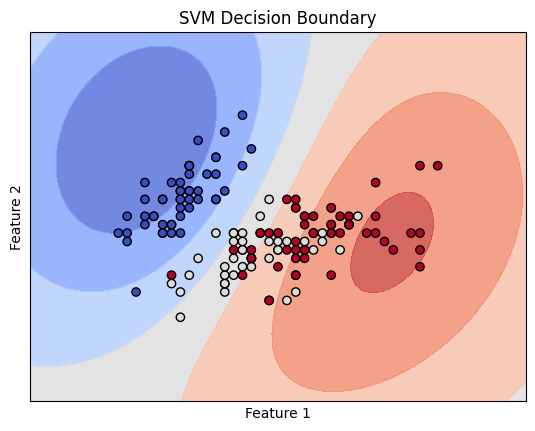

In [6]:
# Load the libraries
import matplotlib.pyplot as plt
import numpy as np
from sklearn.inspection import DecisionBoundaryDisplay

# Create a mesh grid
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Adjust the input to match the expected number of features
# Use all four features for prediction, but only visualize the first two
grid_points = np.c_[xx.ravel(), yy.ravel(), np.zeros((xx.ravel().shape[0], 2))]

# Plot decision boundaries using DecisionBoundaryDisplay
fig, ax = plt.subplots()
disp = DecisionBoundaryDisplay.from_estimator(
    svm_regressor,
    grid_points[:, :2],
    response_method="predict",
    plot_method="contourf",
    cmap=plt.cm.coolwarm,
    alpha=0.8,
    ax=ax
)

# Plot the data points
ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', cmap=plt.cm.coolwarm)
ax.set_title("SVM Decision Boundary")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_xticks(())
ax.set_yticks(())
plt.show()

**Interpretasi:** karena model yang dipakai adalah `SVR`, gambar ini adalah **permukaan nilai prediksi kontinu**, bukan batas kelas diskret: daerah biru = nilai prediksi rendah (≈ kelas 0, *Setosa*), merah = nilai tinggi (≈ kelas 2, *Virginica*), dan kelabu = nilai menengah (≈ kelas 1). Bentuknya halus dan melengkung seperti "bukit" karena kernel RBF. Hanya dua fitur *sepal* yang dipakai, sehingga *Setosa* (kiri) terpisah jelas, sedangkan *Versicolor* dan *Virginica* bercampur di tengah.

### Tambahan: *support vectors* pada model linear dan SVR pada kurva sinus
Bagian pertama menghitung berapa *support vector* yang dipakai `SVC`. Bagian kedua memperlihatkan `SVR` pada data regresi sungguhan (sinus + noise), dengan variasi $\varepsilon$ dan `C`, karena contoh Iris di atas hanya mengilustrasikan API.

Support vector per kelas: {np.str_('setosa'): np.int32(3), np.str_('versicolor'): np.int32(10), np.str_('virginica'): np.int32(8)}
Total support vector    : 21 dari 105 data latih


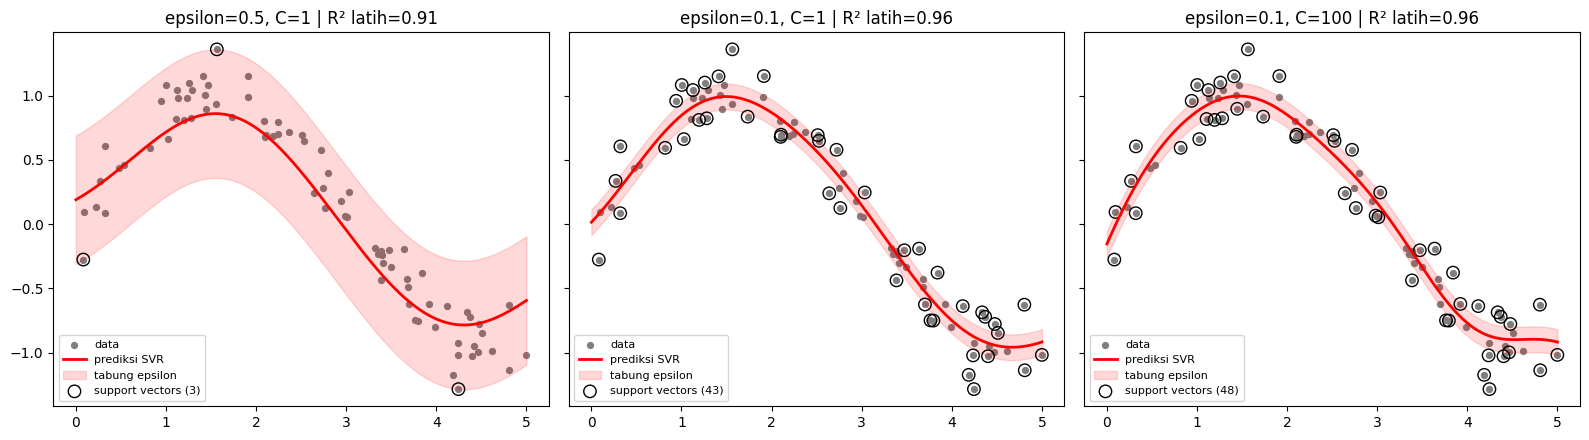

In [7]:
# Tambahan (tidak ada di kode buku): jumlah support vector pada SVC linear
print('Support vector per kelas:', dict(zip(iris.target_names, svm_classifier.n_support_)))
print('Total support vector    :', svm_classifier.n_support_.sum(), 'dari', len(X_train), 'data latih')

# Tambahan: SVR pada data sinus + noise
rng = np.random.RandomState(2024)
Xs = np.sort(5 * rng.rand(80, 1), axis=0)
ys = np.sin(Xs).ravel() + rng.normal(0, 0.15, 80)
x_line = np.linspace(0, 5, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (eps, C_) in zip(axes, [(0.5, 1), (0.1, 1), (0.1, 100)]):
    svr = SVR(kernel='rbf', C=C_, epsilon=eps).fit(Xs, ys)
    y_line = svr.predict(x_line)
    ax.scatter(Xs, ys, s=18, color='gray', label='data')
    ax.plot(x_line, y_line, color='red', lw=2, label='prediksi SVR')
    ax.fill_between(x_line.ravel(), y_line - eps, y_line + eps, color='red', alpha=0.15, label='tabung epsilon')
    ax.scatter(Xs[svr.support_], ys[svr.support_], s=80, facecolors='none', edgecolors='k',
               label=f'support vectors ({len(svr.support_)})')
    ax.set_title(f'epsilon={eps}, C={C_} | R² latih={svr.score(Xs, ys):.2f}')
    ax.legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()

**Interpretasi:**
- **Support vectors:** `SVC` linear hanya memakai **21 dari 105** data latih (3 untuk *setosa*, 10 untuk *versicolor*, 8 untuk *virginica*); sisa ±80% data tidak memengaruhi batas keputusan sama sekali. Perhatikan bahwa kelas yang bercampur (*versicolor*, *virginica*) menyumbang *support vector* lebih banyak.
- **SVR sinus:** dengan $\varepsilon=0{,}5$ tabung sangat lebar sehingga hanya **3** *support vector* dan kurva terlalu halus (R² 0,91; puncak gelombang terpotong). Dengan $\varepsilon=0{,}1$ tabung menyempit, *support vector* menjadi **43** dan kurva mengikuti gelombang (R² 0,96). Menaikkan `C` menjadi 100 hampir tidak menambah R² (tetap 0,96) tetapi *support vector* bertambah menjadi 48 dan kurva mulai mengikuti noise di ujung kanan: `C` lebih besar = model lebih kompleks tanpa keuntungan berarti.

**Konsep penting (dari buku):**
- **Fungsi kernel:** linear, polinomial, dan *radial basis function* (RBF); pilihan kernel bergantung pada kompleksitas data.
- ***Soft margin*:** variabel *slack* mengizinkan sebagian salah klasifikasi sehingga lebih tahan terhadap *outlier*.

### Key Ideas
- SVM mencari batas dengan **margin maksimum**; hanya ***support vectors*** yang menentukan batas tersebut.
- **`C`** mengatur kompromi margin lebar vs kesalahan klasifikasi.
- SVM dapat dipakai untuk klasifikasi (`SVC`) dan regresi (`SVR`).

---
## 2. Fungsi Kernel dan Penerapannya (*Kernel Functions and Their Applications*)

### Teori
Bila data tidak terpisah secara linear, kita dapat memetakannya ke ruang berdimensi lebih tinggi lewat $\phi(x)$ lalu memisahkannya dengan hyperplane di sana. **Trik kernel (*kernel trick*)**: SVM hanya membutuhkan **hasil kali dalam** $\phi(x_i)^\top\phi(x_j)$, sehingga kita cukup menghitung fungsi kernel $K(x_i,x_j)$ **tanpa pernah membentuk $\phi(x)$ secara eksplisit** (efisien, bahkan untuk ruang berdimensi tak hingga). Prediksi SVM dalam bentuk dual:
$$f(x)=\operatorname{sign}\Big(\sum_{i\in SV}\alpha_i y_i K(x_i,x)+b\Big)$$

| Kernel | Rumus $K(x,x')$ | Parameter | Ciri batas keputusan |
|---|---|---|---|
| **Linear** | $x^\top x'$ | `C` | garis/bidang lurus |
| **Polinomial** | $(\gamma\,x^\top x'+r)^{d}$ | `degree` ($d$), `gamma`, `coef0` ($r$) | lengkung berderajat $d$ |
| **RBF (Gaussian)** | $\exp\!\big(-\gamma\lVert x-x'\rVert^2\big)$ | `gamma` | lengkung sangat fleksibel, lokal |
| **Sigmoid** | $\tanh(\gamma\,x^\top x'+r)$ | `gamma`, `coef0` | mirip jaringan saraf; jarang dipakai |

**Parameter `gamma` pada RBF** menentukan "jangkauan" pengaruh satu titik: `gamma` **kecil** → jangkauan luas, batas halus (risiko *underfitting*); `gamma` **besar** → jangkauan sempit, batas bergerigi mengikuti tiap titik (risiko *overfitting*). Nilai bawaan `gamma='scale'` $=\dfrac{1}{n_{\text{fitur}}\cdot\operatorname{Var}(X)}$.

### Getting ready
Dataset Iris lagi. Kernel linear sudah dipakai di subbab 1, sekarang kernel polinomial dan RBF.

In [8]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### How to do it
Kernel **polinomial** (derajat 3):

In [9]:
# Load the model
svm_poly = SVC(kernel='poly', degree=3)

# Train the model
svm_poly.fit(X_train, y_train)

# Make predictions
y_pred_poly = svm_poly.predict(X_test)

# Evaluate the model
accuracy_poly = accuracy_score(y_test, y_pred_poly)
report_poly = classification_report(y_test, y_pred_poly, output_dict=True)

print(f"Polynomial Kernel Accuracy: {accuracy_poly:.2f}")
display(styled_report(report_poly))

Polynomial Kernel Accuracy: 0.96


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,1.000,0.833,0.909,12
2,0.882,1.000,0.938,15
accuracy,0.956,0.956,0.956,1
macro avg,0.961,0.944,0.949,45
weighted avg,0.961,0.956,0.955,45


Kernel **RBF**:

In [10]:
# Load the model
svm_rbf = SVC(kernel='rbf')

# Train the model
svm_rbf.fit(X_train, y_train)

# Make predictions
y_pred_rbf = svm_rbf.predict(X_test)

# Evaluate the model
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
report_rbf = classification_report(y_test, y_pred_rbf, output_dict=True)

print(f"RBF Kernel Accuracy: {accuracy_rbf:.2f}")
display(styled_report(report_rbf))

RBF Kernel Accuracy: 0.91


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.786,0.917,0.846,12
2,0.923,0.800,0.857,15
accuracy,0.911,0.911,0.911,1
macro avg,0.903,0.906,0.901,45
weighted avg,0.917,0.911,0.911,45


**Interpretasi:** pada empat fitur Iris, kernel **polinomial** memberi akurasi **0,96** (43/45), kernel **linear** 0,93, dan kernel **RBF** 0,91 (41/45). Perbedaannya hanya 1–2 sampel dari 45 data uji sehingga tidak boleh dibaca sebagai "polinomial pasti terbaik". Seperti sebelumnya, *Setosa* sempurna pada semua kernel; kernel RBF di sini belum disetel (`C=1`, `gamma='scale'`) dan data belum distandardisasi. Hasil ini menunjukkan bahwa Iris tidak menuntut kernel yang rumit karena datanya hampir terpisah linear.

Visualisasi *decision boundary* tiga kernel pada dua fitur pertama:

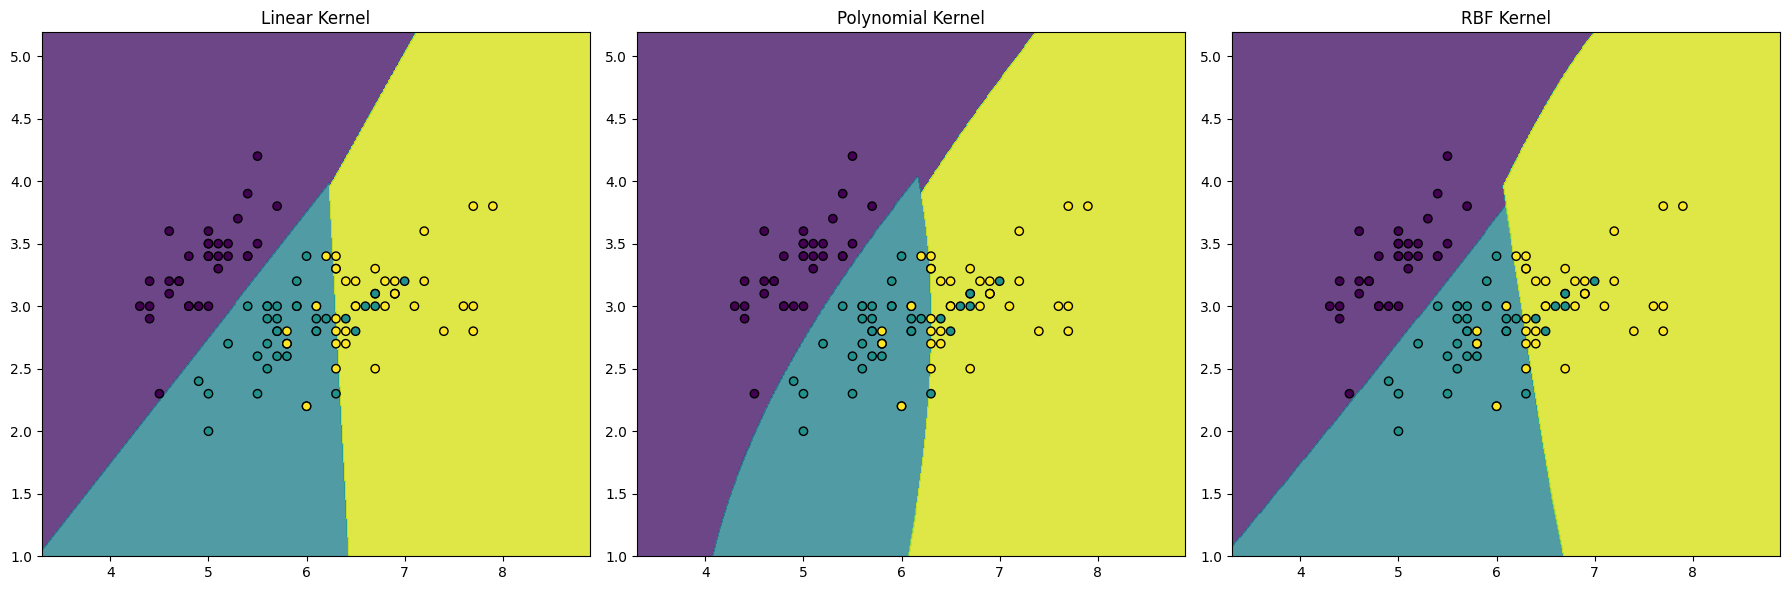

In [11]:
# Create a mesh grid using only the first two features for visualization
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Use only the first two features for prediction
X_train_2d = X_train[:, :2]

# Train new SVM models using only the first two features
svm_linear_2d = SVC(kernel='linear').fit(X_train_2d, y_train)
svm_poly_2d = SVC(kernel='poly').fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel='rbf').fit(X_train_2d, y_train)

# Predict class labels across the grid for each kernel using only the first two features
Z_linear = svm_linear_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z_poly = svm_poly_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z_rbf = svm_rbf_2d.predict(np.c_[xx.ravel(), yy.ravel()])

Z_linear = Z_linear.reshape(xx.shape)
Z_poly = Z_poly.reshape(xx.shape)
Z_rbf = Z_rbf.reshape(xx.shape)

# Plot decision boundaries
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].contourf(xx, yy, Z_linear, alpha=0.8)
axes[0].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
axes[0].set_title("Linear Kernel")

axes[1].contourf(xx, yy, Z_poly, alpha=0.8)
axes[1].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
axes[1].set_title("Polynomial Kernel")

axes[2].contourf(xx, yy, Z_rbf, alpha=0.8)
axes[2].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
axes[2].set_title("RBF Kernel")

plt.tight_layout()
plt.show()

**Interpretasi:** pada dua fitur *sepal* saja, daerah *Setosa* (ungu) terpisah dengan jelas, sedangkan *Versicolor* (hijau kebiruan) dan *Virginica* (kuning) bercampur sehingga ketiga kernel sama-sama membuat kesalahan. Batas **linear** berupa garis lurus; **polinomial** sedikit melengkung (terutama di kiri bawah); **RBF** juga hampir lurus pada data ini. Artinya, untuk data yang hampir terpisah linear, kernel non-linear hanya memberi perbedaan kecil. Perbedaan baru terlihat jelas pada data non-linear di sel berikutnya.

### Tambahan: kernel pada data yang benar-benar non-linear
Iris hampir terpisah linear sehingga perbedaan kernel kurang terlihat. Pada `make_moons` dan `make_circles`, keunggulan kernel non-linear jelas.

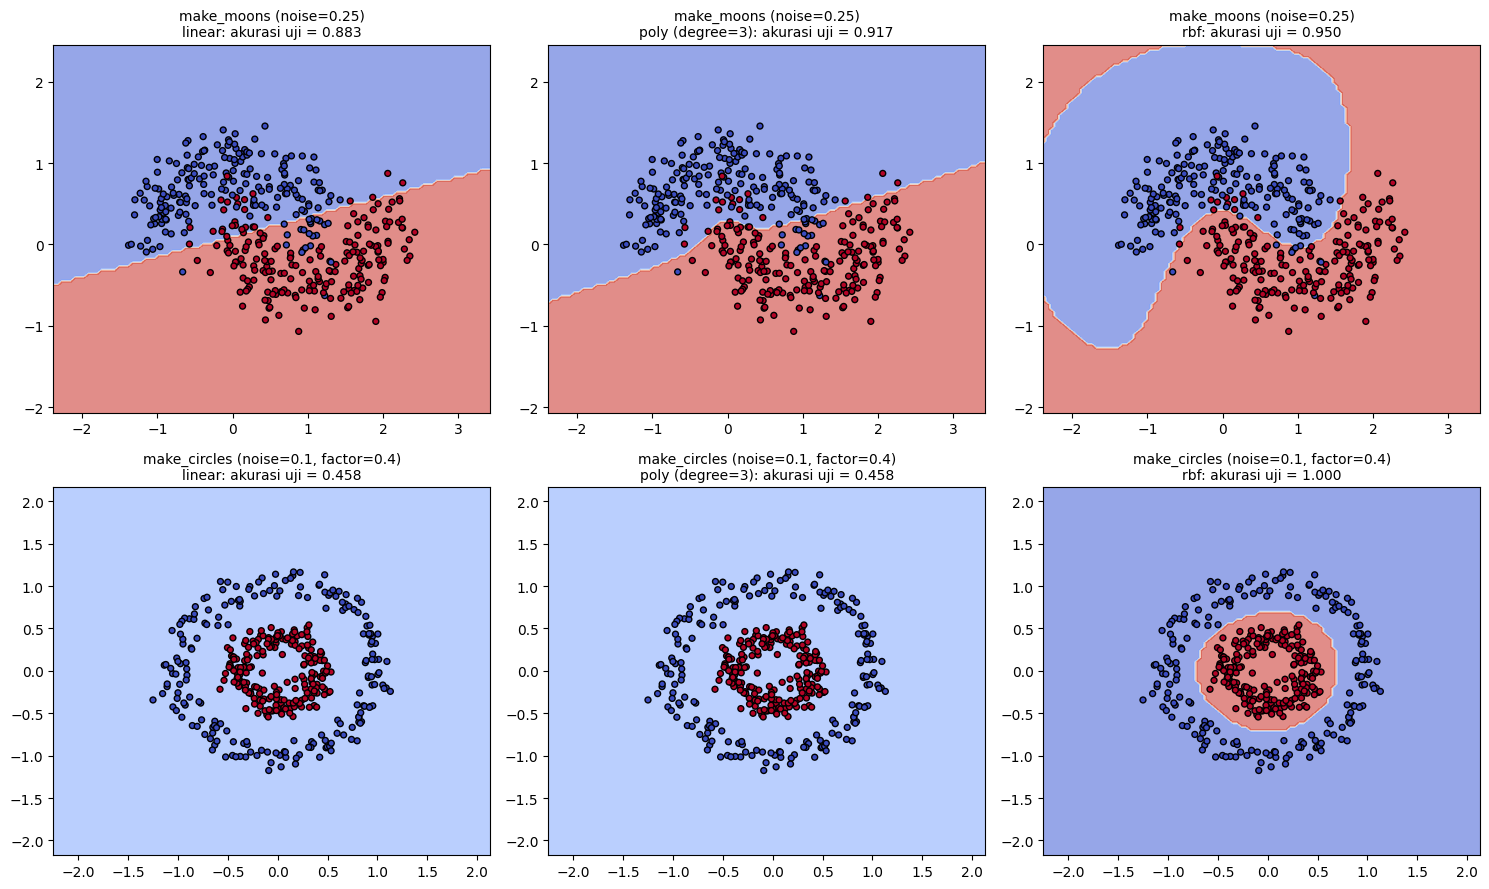

In [12]:
# Tambahan (tidak ada di kode buku): linear vs polinomial vs RBF pada data non-linear
from sklearn.datasets import make_moons, make_circles
from sklearn.inspection import DecisionBoundaryDisplay

datasets = {
    'make_moons (noise=0.25)': make_moons(n_samples=400, noise=0.25, random_state=2024),
    'make_circles (noise=0.1, factor=0.4)': make_circles(n_samples=400, noise=0.1, factor=0.4, random_state=2024),
}
kernels = {'linear': SVC(kernel='linear'), 'poly (degree=3)': SVC(kernel='poly', degree=3), 'rbf': SVC(kernel='rbf')}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
kernel_acc = {}
for r, (dname, (Xd, yd)) in enumerate(datasets.items()):
    Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.3, random_state=2024)
    for c_, (kname, clf) in enumerate(kernels.items()):
        clf.fit(Xd_tr, yd_tr)
        acc = clf.score(Xd_te, yd_te)
        kernel_acc[(dname, kname)] = acc
        ax = axes[r, c_]
        DecisionBoundaryDisplay.from_estimator(clf, Xd, response_method='predict', cmap=plt.cm.coolwarm, alpha=0.6, ax=ax)
        ax.scatter(Xd[:, 0], Xd[:, 1], c=yd, edgecolors='k', cmap=plt.cm.coolwarm, s=18)
        ax.set_title(f'{dname}\n{kname}: akurasi uji = {acc:.3f}', fontsize=10)
plt.tight_layout(); plt.show()

**Interpretasi:** pada `make_moons`, kernel linear mencapai 0,883, polinomial 0,917, dan RBF **0,950**: batas RBF melengkung mengikuti bentuk dua bulan sabit. Pada `make_circles` (satu lingkaran di dalam lingkaran lain), **tidak ada garis lurus yang bisa memisahkan kelas**: kernel linear hanya 0,458 (menebak satu kelas) dan RBF mencapai **1,000**. Kernel polinomial derajat 3 juga gagal (0,458): dengan `coef0=0` polinomial berderajat ganjil adalah fungsi ganjil, tidak bisa membentuk batas lingkaran yang simetris (derajat 2 dapat). Ini contoh nyata keunggulan **trik kernel** dan pentingnya memilih jenis kernel sesuai bentuk data.

### How it works
Fungsi kernel membuat SVM mampu bekerja di ruang berdimensi lebih tinggi **tanpa menghitung koordinat ruang tersebut**, sehingga batas keputusan non-linear di ruang asli bisa diperoleh secara efisien.

- **Linear:** paling sederhana; cukup bila data (hampir) terpisah linear atau fitur sangat banyak.
- **Polinomial:** memetakan data memakai fungsi polinomial; derajat tinggi berisiko *overfitting*.
- **RBF:** memakai fungsi Gaussian; pilihan awal yang baik untuk data non-linear.
- Kernel lain, seperti *sigmoid*, dapat dicoba untuk kasus khusus.

### Key Ideas
- **Trik kernel** memberi batas non-linear tanpa membentuk fitur tambahan secara eksplisit.
- **RBF** adalah kernel serbaguna; **linear** unggul pada dimensi sangat tinggi; **polinomial** cocok bila diketahui hubungan berderajat tertentu.
- Pilih kernel dengan memahami struktur data, lalu setel parameternya (subbab 3).

---
## 3. Menyetel Parameter SVM (*Tuning SVM Parameters*)

### Teori
Kinerja SVM sangat bergantung pada hiperparameter:

| Hiperparameter | Berlaku untuk | Pengaruh |
|---|---|---|
| `C` | semua kernel | kompromi margin vs kesalahan (kecil = lunak, besar = ketat) |
| `kernel` | – | jenis batas keputusan |
| `degree` | `poly` | derajat polinomial (diabaikan oleh kernel lain) |
| `gamma` | `rbf`, `poly`, `sigmoid` | jangkauan pengaruh satu titik |

**`GridSearchCV`** mencoba **semua kombinasi** pada grid, menilai tiap kombinasi dengan *cross-validation*, lalu memilih yang skor rata-ratanya terbaik. Alternatifnya, **`RandomizedSearchCV`** mengambil sampel kombinasi acak sehingga lebih hemat saat ruang pencarian besar. Untuk `C` dan `gamma`, rentang sebaiknya **skala logaritmik** (mis. $10^{-3},10^{-2},\dots,10^{3}$).

### Getting ready

In [13]:
# Load the libraries
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### How to do it
Grid search dengan *5-fold cross-validation* atas `C`, `kernel`, dan `degree`.

In [14]:
# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

# Perform grid search with cross-validation
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Get the best hyperparameters and score
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"Best Parameters: {best_params}")
print(f"Best Cross-Validation Score: {best_score:.2f}")

# Train a new model with the best hyperparameters
best_model = SVC(**best_params)
best_model.fit(X_train, y_train)

# Make predictions with the best model
y_pred = best_model.predict(X_test)

# Evaluate the best model
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
display(styled_report(classification_report(y_test, y_pred, output_dict=True)))

Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Best Cross-Validation Score: 0.99
Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


**Interpretasi:** *grid search* memilih `C=0.1`, `kernel='poly'`, `degree=4` dengan skor *cross-validation* **0,99**, tetapi akurasi pada data uji 0,93 (42/45). Selisih ini wajar: skor CV adalah nilai **terbaik** dari banyak kombinasi (cenderung optimis), sedangkan data uji hanya 45 sampel, jadi satu sampel setara 2,2 poin persentase. Catatan efisiensi: `degree` hanya berlaku untuk kernel `poly`, sehingga untuk `linear` dan `rbf` ketiga nilai `degree` menghasilkan model yang identik (percobaan berulang yang sia-sia); pada praktik nyata, gunakan *grid* terpisah per kernel.

### How it works
Grid search mengevaluasi seluruh kombinasi parameter dengan *cross-validation* agar estimasi performa andal. Berikut efek `C` pada skor CV (kernel RBF, `C` dari $10^{-4}$ sampai $10^{4}$).

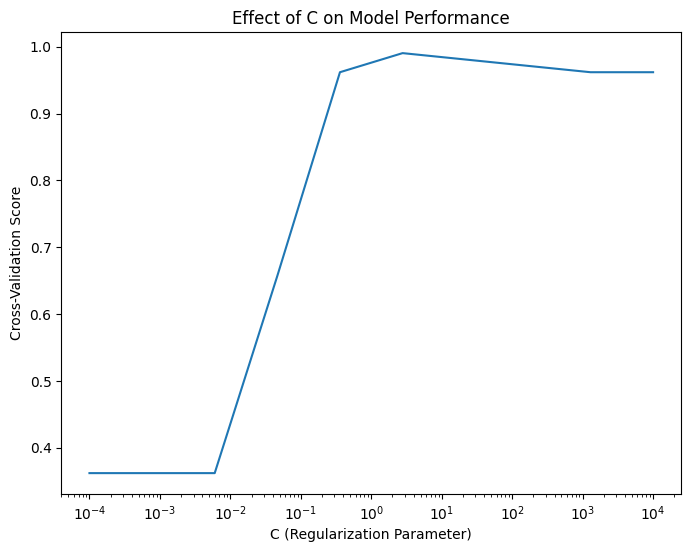

         C  Skor CV
    0.0001    0.362
    0.0008    0.362
    0.0060    0.362
    0.0464    0.657
    0.3594    0.962
    2.7826    0.990
   21.5443    0.981
  166.8101    0.971
 1291.5497    0.962
10000.0000    0.962


In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Perform a grid search with a range of C values for a specific kernel
param_grid_c = {
    'C': np.logspace(-4, 4, 10),
    'kernel': ['rbf']
}
grid_search_c = GridSearchCV(SVC(), param_grid_c, cv=5)
grid_search_c.fit(X_train, y_train)

# Plot the cross-validation scores against C values
plt.figure(figsize=(8, 6))
plt.plot(grid_search_c.param_grid['C'], grid_search_c.cv_results_['mean_test_score'])
plt.xscale('log')
plt.xlabel('C (Regularization Parameter)')
plt.ylabel('Cross-Validation Score')
plt.title('Effect of C on Model Performance')
plt.show()
print(pd.DataFrame({'C': grid_search_c.param_grid['C'].round(4),
                    'Skor CV': grid_search_c.cv_results_['mean_test_score'].round(3)}).to_string(index=False))

**Interpretasi:** kurva ini memperlihatkan tiga fase. (1) **`C` sangat kecil** (≤ 0,006): skor CV hanya 0,362, model terlalu ketat sehingga praktis menebak satu kelas (*underfitting*). (2) **`C` menengah:** skor melonjak ke 0,962 pada `C≈0,36` dan **mencapai puncak 0,990 pada `C≈2,8`**. (3) **`C` besar:** skor turun pelan ke 0,981 lalu 0,971 dan mendatar di 0,962 saat `C ≥ 1.292`. Inilah ***diminishing returns*** seperti yang dikatakan buku: menaikkan `C` melewati titik optimal tidak membantu, bahkan sedikit merugikan karena model mulai menyesuaikan noise.

### Tambahan: interaksi `C` dan `gamma` (kernel RBF) pada Breast Cancer
Untuk RBF, `C` dan `gamma` harus disetel **bersama**. Data distandardisasi di dalam *pipeline* karena SVM peka terhadap skala.

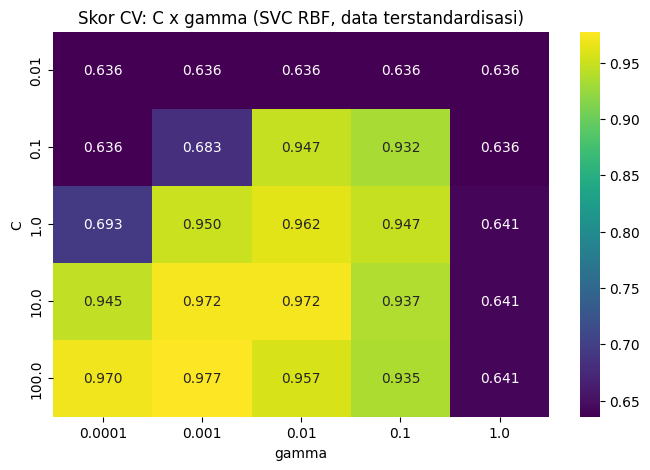

Parameter terbaik: {'svc__C': 100, 'svc__gamma': 0.001}
Skor CV terbaik  : 0.977 | Akurasi uji: 0.982


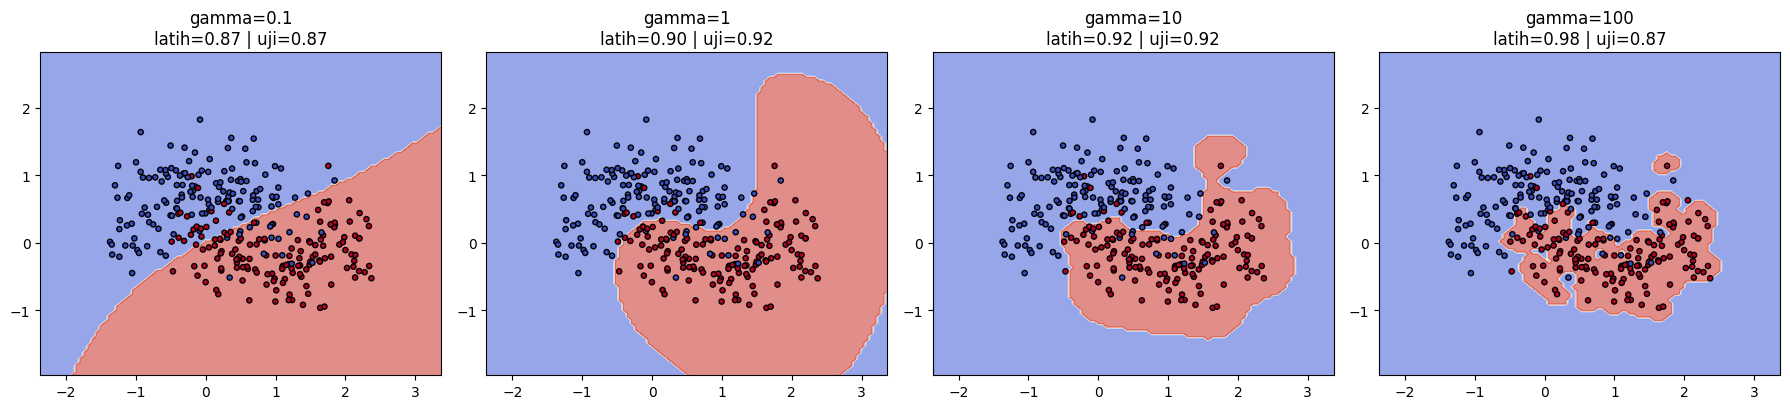

In [16]:
# Tambahan (tidak ada di kode buku): heatmap skor CV untuk kombinasi C x gamma
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

bc = load_breast_cancer()
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(bc.data, bc.target, test_size=0.3, random_state=2024)

pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
param_cg = {'svc__C': [0.01, 0.1, 1, 10, 100], 'svc__gamma': [1e-4, 1e-3, 1e-2, 1e-1, 1]}
gs_cg = GridSearchCV(pipe, param_cg, cv=5).fit(Xb_tr, yb_tr)

res = pd.DataFrame(gs_cg.cv_results_)
heat = res.pivot_table(values='mean_test_score', index='param_svc__C', columns='param_svc__gamma')
plt.figure(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.3f', cmap='viridis')
plt.title('Skor CV: C x gamma (SVC RBF, data terstandardisasi)')
plt.xlabel('gamma'); plt.ylabel('C'); plt.show()

print('Parameter terbaik:', gs_cg.best_params_)
print(f'Skor CV terbaik  : {gs_cg.best_score_:.3f} | Akurasi uji: {gs_cg.score(Xb_te, yb_te):.3f}')

# Tambahan: efek gamma pada data moons (C=1) -> underfitting vs overfitting
Xm, ym = make_moons(n_samples=300, noise=0.3, random_state=2024)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=2024)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, g in zip(axes, [0.1, 1, 10, 100]):
    m = SVC(kernel='rbf', gamma=g, C=1).fit(Xm_tr, ym_tr)
    DecisionBoundaryDisplay.from_estimator(m, Xm, response_method='predict', cmap=plt.cm.coolwarm, alpha=0.6, ax=ax)
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, edgecolors='k', cmap=plt.cm.coolwarm, s=14)
    ax.set_title(f'gamma={g}\nlatih={m.score(Xm_tr, ym_tr):.2f} | uji={m.score(Xm_te, ym_te):.2f}')
plt.tight_layout(); plt.show()

**Interpretasi:** pada Breast Cancer, kombinasi terbaik adalah **`C=100` dengan `gamma=0.001`** (skor CV 0,977; akurasi uji 0,982): `gamma` kecil (batas halus) dikompensasi `C` besar (penalti salah klasifikasi tinggi). Itulah alasan `C` dan `gamma` harus disetel **bersama**. Pada data *moons* (`C=1`): `gamma=0.1` terlalu halus (latih 0,87 / uji 0,87, *underfitting*); `gamma=1` dan `gamma=10` bagus (uji 0,92); `gamma=100` menghasilkan "pulau-pulau" kecil yang menghafal data latih (latih 0,98 tetapi uji turun ke 0,87), yaitu ***overfitting***.

**Konsep penting (dari buku):**
- **Parameter regularisasi (`C`):** mengatur kompromi margin dan kesalahan klasifikasi; `C` besar = model kurang toleran terhadap salah klasifikasi.
- **Parameter kernel:** `degree` untuk polinomial dan `gamma` untuk RBF memengaruhi bentuk pemetaan ke ruang berdimensi tinggi.
- Selain *grid search*, ***randomized search*** dapat dipakai untuk mengambil sampel hiperparameter secara acak.

### Key Ideas
- Setel `C`, `kernel`, `degree`, dan `gamma` dengan **grid search + cross-validation**.
- Peningkatan `C` memberi **hasil yang makin kecil (*diminishing returns*)**, bahkan dapat memicu *overfitting*.
- Gunakan skala **logaritmik** untuk `C` dan `gamma`, dan standardisasi data lewat *pipeline*.

---
## 4. SVM pada Ruang Berdimensi Tinggi (*SVMs in High-Dimensional Spaces*)

### Teori
Dataset "lebar" (*wide*) memiliki fitur sangat banyak dibanding sampel; contohnya pengukuran ratusan sensor pada peristiwa yang jarang terjadi. SVM cocok karena:
- Kompleksitas model ditentukan oleh **margin** dan **jumlah *support vectors***, bukan langsung oleh jumlah fitur (**berbeda dengan banyak model lain yang rentan *curse of dimensionality***, lihat Bab 3).
- Pada dimensi tinggi (terutama bila fitur > sampel), data hampir selalu **dapat dipisahkan secara linear**. Akibatnya **akurasi latih 100% bukan bukti model bagus**; yang menentukan adalah akurasi pada data uji.
- **Kernel linear** adalah *baseline* yang cepat, tetapi `C` perlu disetel (regularisasi lebih kuat); kernel non-linear (RBF) tetap bisa lebih baik bila sinyal tersebar di banyak fitur.

Karena sulit divisualisasikan, data berdimensi tinggi diproyeksikan ke 2D dengan **PCA** (Bab 3) hanya untuk melihat gambaran, bukan untuk melatih model.

### Getting ready
Dataset sintetis: 1.000 sampel, **1.000 fitur** (hanya 50 informatif, 0 redundan).

In [17]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import numpy as np

# Create a synthetic high-dimensional dataset
X, y = make_classification(n_samples=1000, n_features=1000, n_informative=50, n_redundant=0, random_state=2024)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print('Bentuk data latih:', X_train.shape)

Bentuk data latih: (700, 1000)


### How to do it...

In [18]:
# Load the model
svm_model = SVC(kernel='linear')

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
display(styled_report(classification_report(y_test, y_pred, output_dict=True)))

Accuracy: 0.75


,precision,recall,f1-score,support
0,0.765,0.765,0.765,162
1,0.725,0.725,0.725,138
accuracy,0.747,0.747,0.747,1
macro avg,0.745,0.745,0.745,300
weighted avg,0.747,0.747,0.747,300


**Interpretasi:** akurasi hanya **0,75** pada 300 data uji (precision dan recall ≈ 0,73–0,77 untuk kedua kelas), jauh di bawah hasil pada data kecil sebelumnya. Hal ini masuk akal: dari 1.000 fitur hanya 50 yang informatif, sedangkan 950 sisanya noise. Dengan 700 sampel dan 1.000 fitur, data latih selalu bisa dipisahkan sempurna (akurasi latih 1,00 pada tabel "Tambahan"), sehingga model menghafal noise. Kemampuan SVM pada dimensi tinggi berarti ia **masih bisa dilatih dan bekerja**, bukan berarti generalisasinya otomatis bagus.

### How It Works...
SVM menangani data berdimensi tinggi secara efisien. Memvisualisasikannya langsung sulit, maka PCA dipakai untuk memproyeksikan data ke 2D.

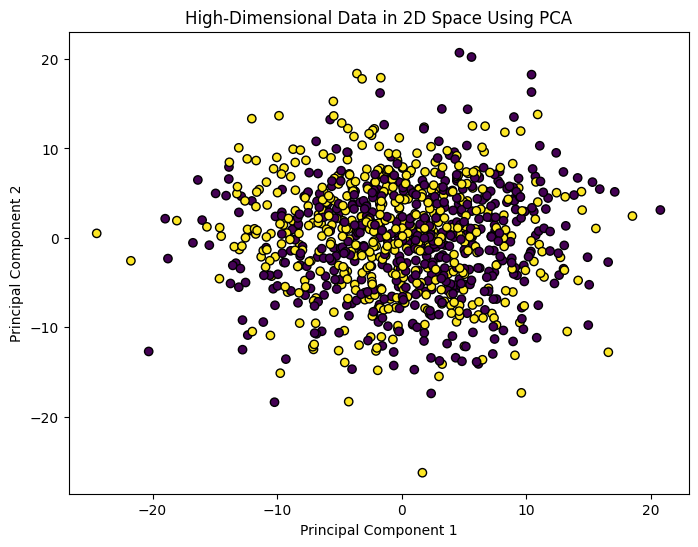

Variansi yang dijelaskan 2 komponen pertama: [0.0245 0.0212] | total = 0.0457


In [19]:
# Import PCA from sklearn.decomposition
from sklearn.decomposition import PCA

# Apply PCA to reduce dimensionality
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plot the reduced data
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, edgecolors='k', marker='o')
plt.title("High-Dimensional Data in 2D Space Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()
print('Variansi yang dijelaskan 2 komponen pertama:', np.round(pca.explained_variance_ratio_, 4), '| total =', round(pca.explained_variance_ratio_.sum(), 4))

**Interpretasi:** dua komponen utama pertama hanya menjelaskan **4,6%** variansi (2,45% + 2,12%), dan titik kedua kelas **menumpuk sepenuhnya** pada proyeksi 2D. Artinya proyeksi PCA tidak menangkap arah yang membedakan kelas; informasi pemisah tersebar di banyak dimensi dan tidak sejajar dengan arah variansi terbesar. Jadi, ketidakterlihatan pemisahan di 2D **tidak** berarti data tidak dapat dipisahkan: SVM tetap mencapai akurasi 0,75–0,89 di dimensi penuh.

### Tambahan: perbandingan kernel dan nilai `C` pada data berdimensi tinggi (akurasi dan waktu latih)

In [20]:
# Tambahan (tidak ada di kode buku)
import time

configs = {'linear (C=1, bawaan)': SVC(kernel='linear', C=1),
           'linear (C=0.0001)': SVC(kernel='linear', C=0.0001),
           'rbf (C=1, bawaan)': SVC(kernel='rbf', C=1),
           'rbf (C=10)': SVC(kernel='rbf', C=10),
           'poly (degree=3)': SVC(kernel='poly', degree=3)}
rows = []
for name, clf in configs.items():
    t0 = time.perf_counter()
    clf.fit(X_train, y_train)
    dur = time.perf_counter() - t0
    rows.append({'Model': name,
                 'Akurasi latih': clf.score(X_train, y_train),
                 'Akurasi uji': clf.score(X_test, y_test),
                 'Support vectors': int(clf.n_support_.sum()),
                 'Waktu latih (detik)': dur})
pd.DataFrame(rows).set_index('Model').round(3)

,Akurasi latih,Akurasi uji,Support vectors,Waktu latih (detik)
Model,,,,
"linear (C=1, bawaan)",1.000,0.747,433,0.385
linear (C=0.0001),0.860,0.803,639,0.402
"rbf (C=1, bawaan)",0.999,0.883,662,0.373
rbf (C=10),1.000,0.893,671,0.344
poly (degree=3),1.000,0.823,700,0.368


**Interpretasi:** hasil ini meluruskan anggapan bahwa "kernel linear selalu cukup" pada dimensi tinggi:
- **Linear, `C=1`:** akurasi latih 1,000 tetapi uji hanya 0,747 (*overfitting*). Karena data terpisah sempurna, menaikkan `C` tidak mengubah apa pun (rezim margin keras).
- **Linear, `C=0.0001`:** regularisasi lebih kuat menurunkan akurasi latih (0,860) tetapi **menaikkan akurasi uji ke 0,803**; kompromi bias-variansi bekerja.
- **RBF:** akurasi uji terbaik, **0,883** (`C=1`) dan **0,893** (`C=10`); **polinomial** 0,823.
- Waktu latih ketiganya serupa (≈ 0,12–0,15 detik) karena hanya 700 sampel; perbedaan waktu baru terasa pada data jauh lebih besar.

### Key Ideas
- SVM efektif saat **jumlah fitur besar** dibanding jumlah sampel.
- **Kernel linear** sering menjadi *baseline* cepat pada dimensi tinggi, tetapi pada fitur > sampel data selalu terpisah (akurasi latih 100%): pantau akurasi uji dan setel `C` serta kernel.
- PCA dipakai untuk **visualisasi**; keterpisahan yang tampak di 2D tidak mencerminkan keterpisahan sebenarnya di dimensi penuh.

---
## 5. Mengevaluasi Model SVM (*Evaluating SVM Models*)

### Teori
Evaluasi model SVM memakai metrik klasifikasi yang sama dengan Bab 6: **akurasi, precision, recall, F1-score**, kurva **ROC**, dan **AUC** (rumus pada Bab 6, subbab 1 dan 5). Hal khusus SVM:
- `SVC` secara bawaan hanya mengeluarkan **label** dan **skor jarak ke hyperplane** (`decision_function`). Untuk memperoleh probabilitas (diperlukan kurva ROC dari `predict_proba`) harus mengaktifkan `probability=True`, yang menambahkan kalibrasi *Platt scaling* dengan *cross-validation* internal (pelatihan lebih lambat).
- Alternatif tanpa biaya tambahan: pakai `decision_function()` langsung untuk ROC, karena ROC hanya membutuhkan **urutan** skor.

### Getting Ready
Dataset Breast Cancer (klasifikasi biner).

In [21]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import classification_report, roc_curve, auc
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### How to Do It...

In [22]:
# Load the model
svm_model = SVC(kernel='linear', probability=True)

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

# Evaluate the model
# Catatan: pada kode buku variabel `accuracy` tidak dihitung di sel ini sehingga yang tercetak
# adalah sisa nilai dari bagian sebelumnya. Di sini dihitung ulang dengan benar.
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)

print(f"Accuracy: {accuracy:.2f}")
display(styled_report(report))

Accuracy: 0.95


,precision,recall,f1-score,support
0,0.926,0.940,0.933,67
1,0.961,0.952,0.957,104
accuracy,0.947,0.947,0.947,1
macro avg,0.944,0.946,0.945,171
weighted avg,0.948,0.947,0.947,171


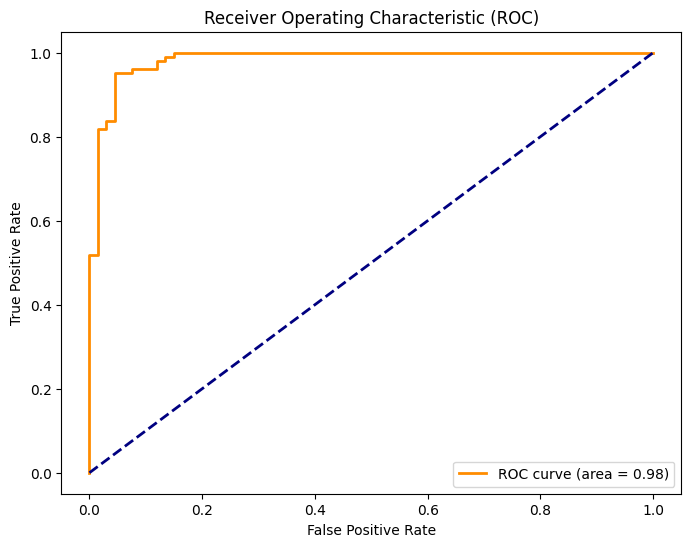

In [23]:
# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Interpretasi:** SVM linear tanpa *scaling* mencapai akurasi **0,95** (162 dari 171) dengan *precision/recall* kelas *Malignant* 0,926/0,940 dan kelas *Benign* 0,961/0,952, serta **AUC ≈ 0,98** (kurva menempel ke sudut kiri-atas). Karena `probability=True`, probabilitas diperoleh dari *Platt scaling*, yaitu logistic regression yang dilatih di atas skor SVM dengan *cross-validation* internal; itu sebabnya pelatihan lebih lambat. (Catatan: pada kode asli buku, variabel `accuracy` tidak dihitung ulang di sel ini sehingga yang tercetak adalah sisa nilai dari bagian sebelumnya; pada notebook ini sudah diperbaiki.)

### Tambahan: pentingnya *scaling* pada SVM
SVM bergantung pada jarak/hasil kali dalam, sehingga fitur berskala besar mendominasi. Berikut perbandingan tanpa dan dengan `StandardScaler` (di dalam *pipeline*), memakai `decision_function` untuk AUC.

,Akurasi (tanpa scaling),AUC (tanpa scaling),Akurasi (dengan scaling),AUC (dengan scaling)
Kernel,,,,
linear,0.947,0.984,0.982,0.999
rbf,0.918,0.976,0.982,0.999


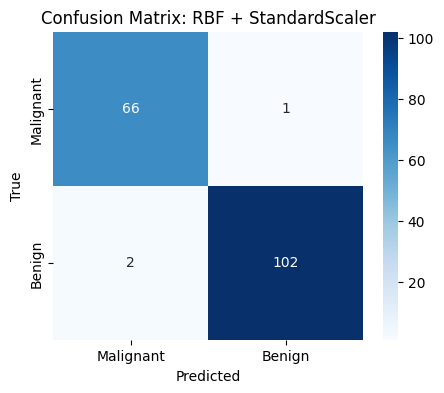

In [24]:
# Tambahan (tidak ada di kode buku): efek scaling pada SVM
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix

rows = []
for kernel in ['linear', 'rbf']:
    raw = SVC(kernel=kernel).fit(X_train, y_train)
    scaled = make_pipeline(StandardScaler(), SVC(kernel=kernel)).fit(X_train, y_train)
    rows.append({'Kernel': kernel,
                 'Akurasi (tanpa scaling)': raw.score(X_test, y_test),
                 'AUC (tanpa scaling)': roc_auc_score(y_test, raw.decision_function(X_test)),
                 'Akurasi (dengan scaling)': scaled.score(X_test, y_test),
                 'AUC (dengan scaling)': roc_auc_score(y_test, scaled.decision_function(X_test))})
display(pd.DataFrame(rows).set_index('Kernel').round(3))

# Confusion matrix model terbaik (RBF + scaling)
best = make_pipeline(StandardScaler(), SVC(kernel='rbf')).fit(X_train, y_train)
cm = confusion_matrix(y_test, best.predict(X_test))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix: RBF + StandardScaler'); plt.show()

**Interpretasi:** standardisasi memperbaiki kedua kernel: **linear** 0,947 → **0,982** (AUC 0,984 → 0,999) dan **RBF** 0,918 → **0,982** (AUC 0,976 → 0,999). Kernel RBF paling diuntungkan (+6,4 poin) karena `gamma='scale'` dihitung dari variansi keseluruhan data yang didominasi fitur berskala besar (mis. `area` bernilai ribuan), sehingga fitur kecil nyaris diabaikan. Model RBF + *scaling* hanya melakukan sekitar 3 kesalahan dari 171 sampel. Pelajaran: untuk SVM, standardisasi bukan opsional.

### How It Works...
Evaluasi SVM memakai: **akurasi**, **precision** (proporsi prediksi positif yang benar), **recall** (proporsi positif sebenarnya yang tertangkap), **F1** (rata-rata harmonik precision dan recall), **kurva ROC** (TPR vs FPR pada berbagai ambang), dan **AUC** (kemampuan membedakan kelas secara keseluruhan). Pilihan metrik bergantung pada tujuan dan biaya kesalahan masalahnya.

### Key Ideas
- Metrik untuk SVM sama dengan model klasifikasi lain; untuk ROC butuh `probability=True` atau `decision_function`.
- **Selalu standardisasi** fitur sebelum SVM.
- Laporkan beberapa metrik sekaligus, bukan akurasi saja.

---
## 6. Latihan Praktik (*Practical Exercises with SVMs*)

Latihan untuk membangun, menyetel, dan mengevaluasi model SVM pada berbagai dataset. Berikut solusi dari berkas *Exercise Solutions* repositori resmi buku, dilengkapi interpretasi.

### Latihan 1: Membangun Klasifikator SVM Sederhana
Menggunakan dataset Iris.

In [25]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a SVM classifier
svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)

# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:")
print(report)

Accuracy: 0.93
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       0.91      0.83      0.87        12
           2       0.88      0.93      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.92      0.92        45
weighted avg       0.93      0.93      0.93        45



**Interpretasi:** akurasi **0,93** (42 dari 45), identik dengan hasil pada subbab 1 karena data, kernel, dan `random_state` sama. *Setosa* sempurna; *Versicolor* recall 0,83 dan *Virginica* precision 0,88 menjadi titik lemah.

### Latihan 2: Menyetel Parameter SVM dengan Grid Search
Menggunakan dataset Breast Cancer.

In [26]:
# Load the libraries
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Define a hyperparameter for grid search
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

# Perform grid search with cross-validation
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)
print('Best Parameters:', grid_search.best_params_)
print(f'Best CV Score  : {grid_search.best_score_:.3f}')

# Train a new model with the best hyperparameters
best_model = SVC(**grid_search.best_params_)
best_model.fit(X_train, y_train)

# Make predictions with the best model
y_pred_best = best_model.predict(X_test)

# Evaluate the best model
accuracy_best = accuracy_score(y_test, y_pred_best)
report_best = classification_report(y_test, y_pred_best)
print(f"Best Model Accuracy: {accuracy_best:.2f}")
print("Best Model Classification Report:")
print(report_best)

Best Parameters: {'C': 1, 'degree': 2, 'kernel': 'linear'}
Best CV Score  : 0.962
Best Model Accuracy: 0.95
Best Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93        67
           1       0.96      0.95      0.96       104

    accuracy                           0.95       171
   macro avg       0.94      0.95      0.94       171
weighted avg       0.95      0.95      0.95       171



**Interpretasi:** pada data **tanpa standardisasi**, *grid search* memilih `C=1`, `kernel='linear'` (skor CV 0,962) dengan akurasi uji **0,95**; `degree=2` tercetak pada parameter terbaik tetapi **diabaikan** oleh kernel linear. Kedua kelas punya precision dan recall 0,93–0,96. Hasil ini lebih rendah daripada 0,982 yang dicapai dengan *scaling* pada subbab 5, memperkuat pesan bahwa standardisasi lebih berpengaruh daripada penyetelan grid yang rumit.

### Latihan 3: Visualisasi *Decision Boundary* SVM
Pada dataset biner sintetis (2 fitur) dengan kernel RBF.

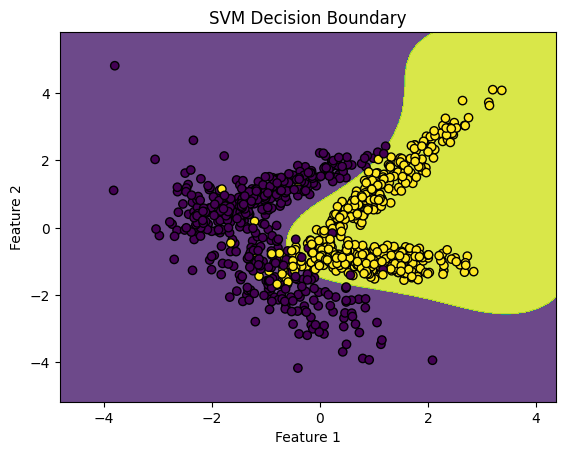

Akurasi uji: 0.977 | jumlah support vectors: 118 dari 700 data latih


In [27]:
# Load libraries for visualization and dataset creation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

# Create a synthetic dataset for binary classification
X, y = make_classification(n_samples=1000, n_features=2, n_classes=2, n_informative=2, n_redundant=0, random_state=2024)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train an SVM model
svm_model = SVC(kernel='rbf')
svm_model.fit(X_train, y_train)

# Create a mesh grid for plotting decision boundaries
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Predict class labels across the grid
Z = svm_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundaries
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
plt.title("SVM Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
print(f'Akurasi uji: {svm_model.score(X_test, y_test):.3f} | jumlah support vectors: {svm_model.n_support_.sum()} dari {len(X_train)} data latih')

**Interpretasi:** SVM RBF mencapai akurasi uji **0,977**, dibanding **0,897** untuk regresi logistik pada data yang sama (Bab 6, Latihan 3). Batas keputusan RBF melengkung mengikuti pengelompokan kelas yang tidak bisa dipisahkan oleh satu garis lurus, dan hanya **118 dari 700** data latih yang menjadi *support vector*. Ini contoh langsung kapan model non-linear (kernel) mengungguli model linear.

---
## 7. Ringkasan Bab

Bab ini memperkenalkan **Support Vector Machine**: model yang mencari batas dengan **margin maksimum**, mampu menangani data non-linear lewat **fungsi kernel**, bekerja baik pada **dimensi tinggi**, dan dapat distel serta dievaluasi dengan perangkat yang sudah dikenal.

### Rangkuman Konsep dan Fungsi
| Subbab | Konsep utama | Kelas/Fungsi scikit-learn |
|---|---|---|
| Pengantar SVM | Hyperplane, margin, *support vectors*, soft margin (`C`), SVR ($\varepsilon$-tube) | `SVC`, `SVR`, `n_support_` |
| Kernel | Trik kernel; linear, polinomial, RBF; `gamma` | `SVC(kernel=, degree=, gamma=)`, `DecisionBoundaryDisplay` |
| Penyetelan parameter | `C`, `kernel`, `degree`, `gamma`; grid/random search | `GridSearchCV`, `RandomizedSearchCV` |
| Dimensi tinggi | Kernel linear efektif saat fitur banyak; PCA untuk visualisasi | `make_classification`, `PCA` |
| Evaluasi | Precision, recall, F1, ROC, AUC; `probability=True` | `classification_report`, `roc_curve`, `auc` |
| Latihan | Klasifikasi Iris, grid search, batas keputusan | `train_test_split`, `contourf` |

**Pesan utama:** **standardisasi fitur** selalu dilakukan lebih dulu; mulai dari kernel **linear** (cepat, baseline) atau **RBF** (serbaguna); setel **`C` dan `gamma` bersama-sama** dalam skala logaritmik dengan *cross-validation*; dan waspadai biaya komputasi pada data dengan jumlah sampel sangat besar.